ZEROQ AI - XGBOOST OPTIMIZED MODEL

Loading datasets...
Training: (17776, 10038)
Validation: (2488, 10038)
Testing: (3571, 10038)

Class distribution:
Training complaint percentage: 21.07
Validation complaint percentage: 21.74
Testing complaint percentage: 21.03

Majority-class test accuracy: 78.97 %

TRAINING XGBOOST - POSITIVE CLASS WEIGHT: 1.0
Training time: 60.69 seconds
Best threshold: 0.48
Validation accuracy: 78.3 %
Validation precision: 0.6667
Validation recall: 0.0037
Validation F1: 0.0074
Validation ROC-AUC: 0.5208

TRAINING XGBOOST - POSITIVE CLASS WEIGHT: 1.5
Training time: 58.33 seconds
Best threshold: 0.56
Validation accuracy: 78.34 %
Validation precision: 1.0
Validation recall: 0.0037
Validation F1: 0.0074
Validation ROC-AUC: 0.521

TRAINING XGBOOST - POSITIVE CLASS WEIGHT: 2.0
Training time: 58.81 seconds
Best threshold: 0.61
Validation accuracy: 78.34 %
Validation precision: 0.75
Validation recall: 0.0055
Validation F1: 0.011
Validation ROC-AUC: 0.5181

TRAINING XGBOOS

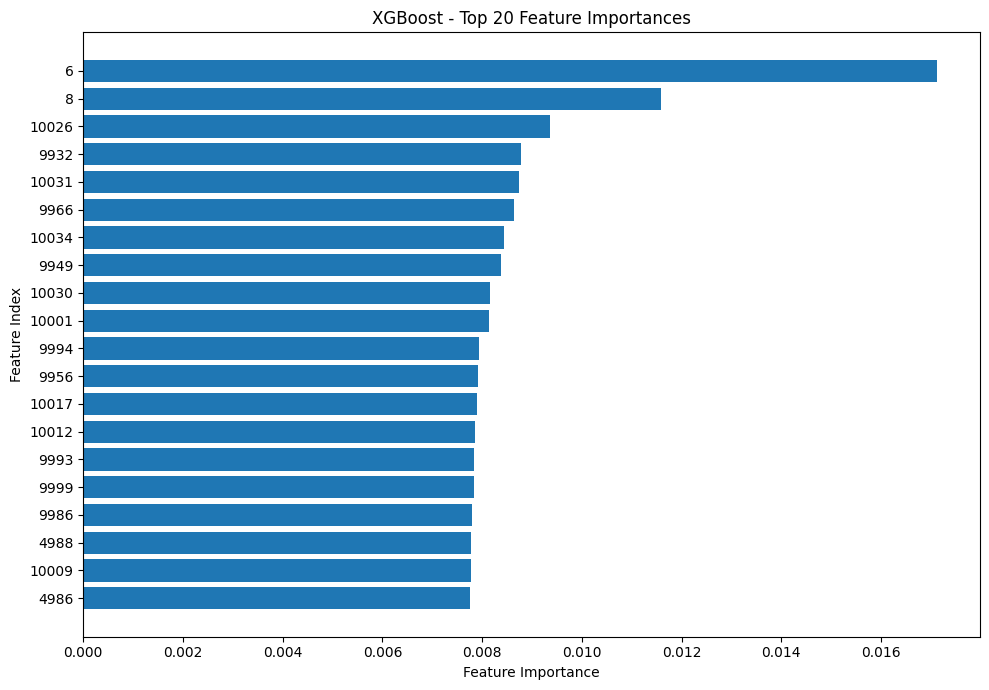


XGBOOST EXPERIMENT COMPLETED
Selected class weight: 2.5
Test accuracy: 78.91 %
Majority baseline: 78.97 %
Saved outputs to:
D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_training\xgboost_optimized


In [4]:

# ================================================================
# ZEROQ AI - XGBOOST WITH CLASS WEIGHT AND THRESHOLD OPTIMIZATION
# ================================================================

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from scipy.sparse import load_npz
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

warnings.filterwarnings("ignore")

# ================================================================
# 1. PATH CONFIGURATION
# ================================================================

PROJECT_DIR = Path(
    r"D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training"
)

DATA_DIR = PROJECT_DIR / "model_ready_data"

OUTPUT_DIR = (
    PROJECT_DIR / "model_training" / "xgboost_optimized"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("ZEROQ AI - XGBOOST OPTIMIZED MODEL")
print("=" * 70)


# ================================================================
# 2. LOAD DATA
# ================================================================

print("\nLoading datasets...")

X_train = load_npz(DATA_DIR / "X_train.npz")
X_val = load_npz(DATA_DIR / "X_validation.npz")
X_test = load_npz(DATA_DIR / "X_test.npz")

y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_validation.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nClass distribution:")
print("Training complaint percentage:", round(y_train.mean() * 100, 2))
print("Validation complaint percentage:", round(y_val.mean() * 100, 2))
print("Testing complaint percentage:", round(y_test.mean() * 100, 2))


# ================================================================
# 3. BASELINE ACCURACY
# ================================================================

majority_baseline = max(
    np.mean(y_test == 0),
    np.mean(y_test == 1)
)

print("\nMajority-class test accuracy:",
      round(majority_baseline * 100, 2), "%")


# ================================================================
# 4. CLASS WEIGHT EXPERIMENTS
# ================================================================

# Positive class = Complaint
# Negative class = No Complaint

# 3.75 is the approximate class imbalance ratio.
# We test different weights rather than assuming 3.75 is best.

CLASS_WEIGHTS = [1.0, 1.5, 2.0, 2.5, 3.0, 3.75]

results = []
trained_models = {}

for weight in CLASS_WEIGHTS:

    print("\n" + "=" * 70)
    print(f"TRAINING XGBOOST - POSITIVE CLASS WEIGHT: {weight}")
    print("=" * 70)

    model = XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=0.1,
        reg_alpha=0.1,
        reg_lambda=5.0,
        scale_pos_weight=weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    duration = time.time() - start_time

    val_prob = model.predict_proba(X_val)[:, 1]

    # Find the threshold with maximum validation accuracy.
    thresholds = np.arange(0.05, 0.96, 0.01)

    threshold_results = []

    for threshold in thresholds:

        val_pred = (val_prob >= threshold).astype(int)

        threshold_results.append({
            "threshold": threshold,
            "accuracy": accuracy_score(y_val, val_pred),
            "precision": precision_score(
                y_val, val_pred, zero_division=0
            ),
            "recall": recall_score(
                y_val, val_pred, zero_division=0
            ),
            "f1": f1_score(
                y_val, val_pred, zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_val, val_pred
            )
        })

    threshold_df = pd.DataFrame(threshold_results)

    # Select threshold by validation accuracy.
    # If tied, prefer higher F1.
    best_row = threshold_df.sort_values(
        ["accuracy", "f1"],
        ascending=[False, False]
    ).iloc[0]

    best_threshold = float(best_row["threshold"])

    val_pred = (val_prob >= best_threshold).astype(int)

    print("Training time:", round(duration, 2), "seconds")
    print("Best threshold:", round(best_threshold, 3))
    print("Validation accuracy:",
          round(best_row["accuracy"] * 100, 2), "%")
    print("Validation precision:",
          round(best_row["precision"], 4))
    print("Validation recall:",
          round(best_row["recall"], 4))
    print("Validation F1:",
          round(best_row["f1"], 4))
    print("Validation ROC-AUC:",
          round(roc_auc_score(y_val, val_prob), 4))

    results.append({
        "class_weight": weight,
        "best_threshold": best_threshold,
        "validation_accuracy": best_row["accuracy"],
        "validation_precision": best_row["precision"],
        "validation_recall": best_row["recall"],
        "validation_f1": best_row["f1"],
        "validation_balanced_accuracy":
            best_row["balanced_accuracy"],
        "validation_roc_auc":
            roc_auc_score(y_val, val_prob),
        "training_time_seconds": duration
    })

    trained_models[weight] = {
        "model": model,
        "threshold": best_threshold,
        "validation_accuracy": best_row["accuracy"]
    }


# ================================================================
# 5. COMPARE CLASS WEIGHTS
# ================================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["validation_accuracy", "validation_f1"],
    ascending=[False, False]
)

print("\n" + "=" * 70)
print("CLASS WEIGHT COMPARISON")
print("=" * 70)

print(results_df.to_string(index=False))

results_df.to_csv(
    OUTPUT_DIR / "class_weight_comparison.csv",
    index=False
)


# ================================================================
# 6. SELECT BEST MODEL
# ================================================================

best_weight = float(results_df.iloc[0]["class_weight"])

best_model = trained_models[best_weight]["model"]
best_threshold = trained_models[best_weight]["threshold"]

print("\nSelected positive class weight:", best_weight)
print("Selected threshold:", round(best_threshold, 4))


# ================================================================
# 7. FINAL EVALUATION
# ================================================================

# Test set is used only after model and threshold selection.

test_prob = best_model.predict_proba(X_test)[:, 1]

test_pred = (test_prob >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE")
print("=" * 70)

print("Accuracy:",
      round(accuracy_score(y_test, test_pred) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_test, test_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, test_pred, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_test, test_pred, zero_division=0), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, test_pred), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, test_prob), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["No Complaint", "Complaint"],
        zero_division=0
    )
)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


# ================================================================
# 8. SAVE MODEL AND PREDICTIONS
# ================================================================

joblib.dump(
    best_model,
    OUTPUT_DIR / "xgboost_best_model.joblib"
)

joblib.dump(
    best_threshold,
    OUTPUT_DIR / "optimal_threshold.joblib"
)

np.save(
    OUTPUT_DIR / "test_probabilities.npy",
    test_prob
)

np.save(
    OUTPUT_DIR / "test_predictions.npy",
    test_pred
)

prediction_df = pd.DataFrame({
    "actual_complaint": y_test,
    "predicted_probability": test_prob,
    "predicted_complaint": test_pred
})

prediction_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)


# ================================================================
# 9. FEATURE IMPORTANCE
# ================================================================

importance_df = pd.DataFrame({
    "feature_index": np.arange(X_train.shape[1]),
    "importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

print("\nTop 20 Important Features:")
print(importance_df.head(20).to_string(index=False))

plt.figure(figsize=(10, 7))

top_features = importance_df.head(20).sort_values(
    "importance"
)

plt.barh(
    top_features["feature_index"].astype(str),
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature Index")
plt.title("XGBoost - Top 20 Feature Importances")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top_20_feature_importance.png",
    dpi=300
)

plt.show()


# ================================================================
# 10. SAVE FINAL EXPERIMENT SUMMARY
# ================================================================

summary = pd.DataFrame([{
    "model": "XGBoost Classifier",
    "selected_class_weight": best_weight,
    "selected_threshold": best_threshold,
    "test_accuracy": accuracy_score(y_test, test_pred),
    "test_precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "test_recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "test_f1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "test_roc_auc": roc_auc_score(y_test, test_prob),
    "test_pr_auc": average_precision_score(y_test, test_prob),
    "majority_baseline_accuracy": majority_baseline
}])

summary.to_csv(
    OUTPUT_DIR / "final_model_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("XGBOOST EXPERIMENT COMPLETED")
print("=" * 70)

print("Selected class weight:", best_weight)
print("Test accuracy:",
      round(accuracy_score(y_test, test_pred) * 100, 2), "%")

print("Majority baseline:",
      round(majority_baseline * 100, 2), "%")

print("Saved outputs to:")
print(OUTPUT_DIR)


ZEROQ AI - ADVANCED XGBOOST OPTIMIZATION

Loading datasets...
Training: (17776, 10038)
Validation: (2488, 10038)
Testing: (3571, 10038)

Class distribution:
Training complaint rate: 21.07 %
Validation complaint rate: 21.74 %
Testing complaint rate: 21.03 %

Majority-class baseline accuracy: 78.97 %

EXPERIMENT 1/40
Parameters: {'max_depth': 3, 'min_child_weight': 3, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8, 'gamma': 0.1, 'reg_alpha': 0.1, 'reg_lambda': 5}
Positive class weight: 1.0
Training time: 8.68 seconds
Best iteration: 3
Best threshold: 0.21
Validation accuracy: 54.82 %
Validation recall: 0.5028
Validation F1: 0.3261
Validation ROC-AUC: 0.5409

EXPERIMENT 2/40
Parameters: {'max_depth': 3, 'min_child_weight': 3, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8, 'gamma': 0.1, 'reg_alpha': 0.1, 'reg_lambda': 5}
Positive class weight: 1.5
Training time: 6.76 seconds
Best iteration: 3
Best threshold: 0.05
Validation accuracy: 21.74 %
Validation 

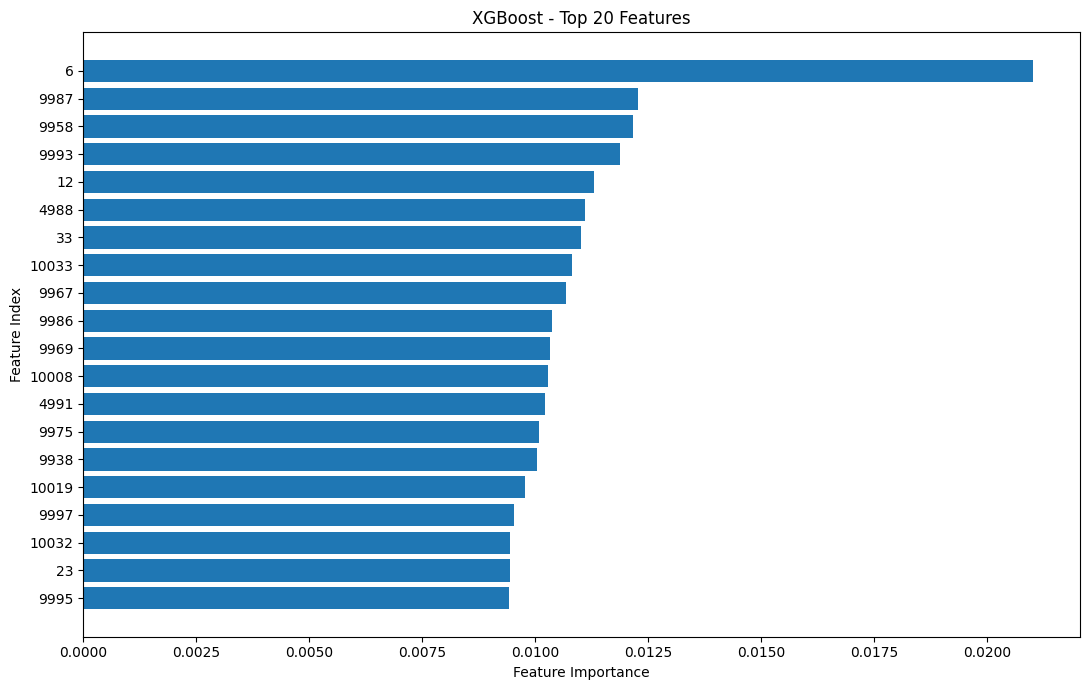


ADVANCED XGBOOST TRAINING COMPLETED
Output directory:
D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_training\xgboost_advanced
best_threshold.joblib
best_xgboost_model.joblib
feature_importance.csv
final_xgboost_summary.csv
test_predictions.csv
test_predictions.npy
test_probabilities.npy
top_features.png
xgboost_hyperparameter_comparison.csv


In [1]:

# =====================================================================
# ZEROQ AI - ADVANCED XGBOOST OPTIMIZATION
# Hyperparameter tuning + Class weighting + Early stopping
# =====================================================================

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from scipy.sparse import load_npz

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_DIR = Path(
    r"D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training"
)

DATA_DIR = PROJECT_DIR / "model_ready_data"

OUTPUT_DIR = (
    PROJECT_DIR / "model_training" / "xgboost_advanced"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("=" * 75)
print("ZEROQ AI - ADVANCED XGBOOST OPTIMIZATION")
print("=" * 75)


# =====================================================================
# 2. LOAD DATA
# =====================================================================

print("\nLoading datasets...")

X_train = load_npz(DATA_DIR / "X_train.npz").tocsr()
X_val = load_npz(DATA_DIR / "X_validation.npz").tocsr()
X_test = load_npz(DATA_DIR / "X_test.npz").tocsr()

y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_validation.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nClass distribution:")
print("Training complaint rate:", round(y_train.mean() * 100, 2), "%")
print("Validation complaint rate:", round(y_val.mean() * 100, 2), "%")
print("Testing complaint rate:", round(y_test.mean() * 100, 2), "%")


# =====================================================================
# 3. BASELINE
# =====================================================================

majority_baseline = max(
    np.mean(y_test == 0),
    np.mean(y_test == 1)
)

print("\nMajority-class baseline accuracy:",
      round(majority_baseline * 100, 2), "%")


# =====================================================================
# 4. HYPERPARAMETER CONFIGURATIONS
# =====================================================================

# Test different tree structures and regularization settings.

PARAMETER_CONFIGS = [
    {
        "max_depth": 3,
        "min_child_weight": 3,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "gamma": 0.1,
        "reg_alpha": 0.1,
        "reg_lambda": 5
    },
    {
        "max_depth": 4,
        "min_child_weight": 3,
        "learning_rate": 0.03,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "gamma": 0.1,
        "reg_alpha": 0.1,
        "reg_lambda": 5
    },
    {
        "max_depth": 5,
        "min_child_weight": 5,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "gamma": 0.2,
        "reg_alpha": 0.5,
        "reg_lambda": 8
    },
    {
        "max_depth": 6,
        "min_child_weight": 5,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "gamma": 0.2,
        "reg_alpha": 0.5,
        "reg_lambda": 10
    },
    {
        "max_depth": 4,
        "min_child_weight": 7,
        "learning_rate": 0.05,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "gamma": 0.3,
        "reg_alpha": 1,
        "reg_lambda": 10
    },
    {
        "max_depth": 5,
        "min_child_weight": 3,
        "learning_rate": 0.05,
        "subsample": 0.85,
        "colsample_bytree": 0.75,
        "gamma": 0,
        "reg_alpha": 0.1,
        "reg_lambda": 5
    },
    {
        "max_depth": 3,
        "min_child_weight": 7,
        "learning_rate": 0.05,
        "subsample": 0.9,
        "colsample_bytree": 0.8,
        "gamma": 0.2,
        "reg_alpha": 1,
        "reg_lambda": 10
    },
    {
        "max_depth": 6,
        "min_child_weight": 7,
        "learning_rate": 0.05,
        "subsample": 0.85,
        "colsample_bytree": 0.75,
        "gamma": 0.3,
        "reg_alpha": 1,
        "reg_lambda": 8
    }
]

CLASS_WEIGHTS = [1.0, 1.5, 2.0, 2.5, 3.75]

results = []
trained_models = {}

experiment_number = 0
total_experiments = len(PARAMETER_CONFIGS) * len(CLASS_WEIGHTS)


# =====================================================================
# 5. TRAIN AND TUNE MODELS
# =====================================================================

for params in PARAMETER_CONFIGS:

    for positive_weight in CLASS_WEIGHTS:

        experiment_number += 1

        print("\n" + "=" * 75)
        print(
            f"EXPERIMENT {experiment_number}/{total_experiments}"
        )

        print("Parameters:", params)
        print("Positive class weight:", positive_weight)

        model = XGBClassifier(
            n_estimators=1000,
            max_depth=params["max_depth"],
            min_child_weight=params["min_child_weight"],
            learning_rate=params["learning_rate"],
            subsample=params["subsample"],
            colsample_bytree=params["colsample_bytree"],
            gamma=params["gamma"],
            reg_alpha=params["reg_alpha"],
            reg_lambda=params["reg_lambda"],
            scale_pos_weight=positive_weight,
            objective="binary:logistic",
            eval_metric="auc",
            early_stopping_rounds=50,
            tree_method="hist",
            max_bin=256,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        start_time = time.time()

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        duration = time.time() - start_time

        # Validation probabilities
        val_prob = model.predict_proba(X_val)[:, 1]

        # Evaluate thresholds
        threshold_results = []

        for threshold in np.arange(0.05, 0.951, 0.01):

            val_pred = (val_prob >= threshold).astype(int)

            threshold_results.append({
                "threshold": threshold,
                "accuracy": accuracy_score(y_val, val_pred),
                "precision": precision_score(
                    y_val, val_pred, zero_division=0
                ),
                "recall": recall_score(
                    y_val, val_pred, zero_division=0
                ),
                "f1": f1_score(
                    y_val, val_pred, zero_division=0
                ),
                "balanced_accuracy": balanced_accuracy_score(
                    y_val, val_pred
                )
            })

        threshold_df = pd.DataFrame(threshold_results)

        # Prevent a trivial all-negative model from winning.
        # Require at least 50% recall on validation.
        eligible = threshold_df[
            threshold_df["recall"] >= 0.50
        ]

        if eligible.empty:
            eligible = threshold_df

        best_row = eligible.sort_values(
            ["accuracy", "f1", "balanced_accuracy"],
            ascending=[False, False, False]
        ).iloc[0]

        best_threshold = float(best_row["threshold"])

        val_roc_auc = roc_auc_score(y_val, val_prob)

        val_pr_auc = average_precision_score(y_val, val_prob)

        result = {
            "experiment": experiment_number,
            "positive_weight": positive_weight,
            **params,
            "threshold": best_threshold,
            "validation_accuracy": best_row["accuracy"],
            "validation_precision": best_row["precision"],
            "validation_recall": best_row["recall"],
            "validation_f1": best_row["f1"],
            "validation_balanced_accuracy":
                best_row["balanced_accuracy"],
            "validation_roc_auc": val_roc_auc,
            "validation_pr_auc": val_pr_auc,
            "best_iteration": model.best_iteration,
            "training_time": duration
        }

        results.append(result)

        trained_models[experiment_number] = {
            "model": model,
            "threshold": best_threshold,
            "validation_accuracy": best_row["accuracy"],
            "validation_f1": best_row["f1"],
            "validation_roc_auc": val_roc_auc
        }

        print("Training time:", round(duration, 2), "seconds")
        print("Best iteration:", model.best_iteration)
        print("Best threshold:", round(best_threshold, 3))
        print(
            "Validation accuracy:",
            round(best_row["accuracy"] * 100, 2), "%"
        )
        print("Validation recall:", round(best_row["recall"], 4))
        print("Validation F1:", round(best_row["f1"], 4))
        print("Validation ROC-AUC:", round(val_roc_auc, 4))


# =====================================================================
# 6. COMPARE ALL EXPERIMENTS
# =====================================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=[
        "validation_accuracy",
        "validation_f1",
        "validation_roc_auc"
    ],
    ascending=[False, False, False]
).reset_index(drop=True)

print("\n" + "=" * 75)
print("HYPERPARAMETER COMPARISON")
print("=" * 75)

print(results_df.to_string(index=False))

results_df.to_csv(
    OUTPUT_DIR / "xgboost_hyperparameter_comparison.csv",
    index=False
)


# =====================================================================
# 7. SELECT BEST MODEL USING VALIDATION ONLY
# =====================================================================

best_experiment = int(results_df.iloc[0]["experiment"])

best_model = trained_models[best_experiment]["model"]

best_threshold = trained_models[best_experiment]["threshold"]

print("\nSelected experiment:", best_experiment)
print("Selected threshold:", best_threshold)


# =====================================================================
# 8. FINAL TEST EVALUATION
# =====================================================================

test_prob = best_model.predict_proba(X_test)[:, 1]

test_pred = (test_prob >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

test_accuracy = accuracy_score(y_test, test_pred)

test_precision = precision_score(
    y_test, test_pred, zero_division=0
)

test_recall = recall_score(
    y_test, test_pred, zero_division=0
)

test_f1 = f1_score(
    y_test, test_pred, zero_division=0
)

test_roc_auc = roc_auc_score(y_test, test_prob)

test_pr_auc = average_precision_score(y_test, test_prob)

test_balanced_accuracy = balanced_accuracy_score(
    y_test, test_pred
)

print("\n" + "=" * 75)
print("FINAL XGBOOST TEST RESULTS")
print("=" * 75)

print(f"Accuracy: {test_accuracy * 100:.2f}%")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1 Score: {test_f1:.4f}")
print(f"Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"ROC-AUC: {test_roc_auc:.4f}")
print(f"PR-AUC: {test_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["No Complaint", "Complaint"],
        zero_division=0
    )
)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nMajority baseline:", round(majority_baseline * 100, 2), "%")
print(
    "Accuracy improvement:",
    round((test_accuracy - majority_baseline) * 100, 2),
    "percentage points"
)


# =====================================================================
# 9. SAVE MODEL AND OUTPUTS
# =====================================================================

joblib.dump(
    best_model,
    OUTPUT_DIR / "best_xgboost_model.joblib"
)

joblib.dump(
    best_threshold,
    OUTPUT_DIR / "best_threshold.joblib"
)

np.save(
    OUTPUT_DIR / "test_probabilities.npy",
    test_prob
)

np.save(
    OUTPUT_DIR / "test_predictions.npy",
    test_pred
)

prediction_df = pd.DataFrame({
    "actual_complaint": y_test,
    "predicted_probability": test_prob,
    "predicted_complaint": test_pred
})

prediction_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)


# =====================================================================
# 10. FEATURE IMPORTANCE
# =====================================================================

importance_df = pd.DataFrame({
    "feature_index": np.arange(X_train.shape[1]),
    "importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

top_features = importance_df.head(20).sort_values(
    "importance"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["feature_index"].astype(str),
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature Index")
plt.title("XGBoost - Top 20 Features")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top_features.png",
    dpi=300
)

plt.show()


# =====================================================================
# 11. FINAL SUMMARY
# =====================================================================

summary = pd.DataFrame([{
    "Model": "Advanced XGBoost",
    "Selected_Experiment": best_experiment,
    "Threshold": best_threshold,
    "Test_Accuracy": test_accuracy,
    "Test_Precision": test_precision,
    "Test_Recall": test_recall,
    "Test_F1": test_f1,
    "Test_Balanced_Accuracy": test_balanced_accuracy,
    "Test_ROC_AUC": test_roc_auc,
    "Test_PR_AUC": test_pr_auc,
    "Majority_Baseline": majority_baseline,
    "TP": tp,
    "TN": tn,
    "FP": fp,
    "FN": fn
}])

summary.to_csv(
    OUTPUT_DIR / "final_xgboost_summary.csv",
    index=False
)

print("\n" + "=" * 75)
print("ADVANCED XGBOOST TRAINING COMPLETED")
print("=" * 75)

print("Output directory:")
print(OUTPUT_DIR)

for file in OUTPUT_DIR.iterdir():
    print(file.name)


ZEROQ AI - FINAL XGBOOST MODEL

Loading datasets...
Training: (17776, 10038)
Validation: (2488, 10038)
Testing: (3571, 10038)

Complaint distribution:
Training: 3745 complaints, 14031 non-complaints, 21.07% complaints
Validation: 541 complaints, 1947 non-complaints, 21.74% complaints
Testing: 751 complaints, 2820 non-complaints, 21.03% complaints

Majority baseline accuracy: 78.97 %

Training final XGBoost model...

Training completed.
Training duration: 34.75 seconds
Best iteration: 219

Validation ROC-AUC: 0.5469
Validation PR-AUC: 0.2581

Best validation threshold: 0.325
Validation accuracy: 78.34 %
Validation precision: 0.6667
Validation recall: 0.0074
Validation F1: 0.0146
Validation balanced accuracy: 0.5032
Predicted complaint percentage: 0.24 %

FINAL TEST PERFORMANCE
Accuracy: 78.91%
Precision: 0.2500
Recall: 0.0013
F1 Score: 0.0026
Balanced Accuracy: 0.5001
ROC-AUC: 0.5370
PR-AUC: 0.2348

Confusion Matrix:
[[2817    3]
 [ 750    1]]

Classification Report:
              preci

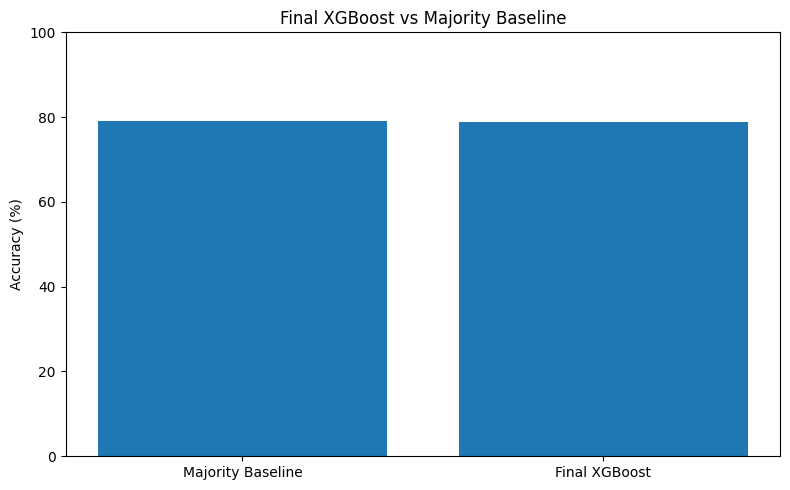


FINAL XGBOOST PIPELINE COMPLETED

Saved outputs:
feature_importance.csv
final_accuracy_comparison.png
final_model_metrics.csv
final_threshold.joblib
final_xgboost_model.joblib
test_predictions.npy
test_prediction_report.csv
test_probabilities.npy
validation_threshold_analysis.csv

Output directory:
D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_training\final_xgboost


In [2]:

# =====================================================================
# ZEROQ AI - FINAL OPTIMIZED XGBOOST MODEL
# Generalization | Regularization | Accuracy Optimization
# =====================================================================

from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from scipy.sparse import load_npz
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CONFIGURATION
# =====================================================================

PROJECT_DIR = Path(
    r"D:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training"
)

DATA_DIR = PROJECT_DIR / "model_ready_data"

OUTPUT_DIR = (
    PROJECT_DIR / "model_training" / "final_xgboost"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("=" * 75)
print("ZEROQ AI - FINAL XGBOOST MODEL")
print("=" * 75)


# =====================================================================
# 2. LOAD DATA
# =====================================================================

print("\nLoading datasets...")

X_train = load_npz(DATA_DIR / "X_train.npz").tocsr()
X_val = load_npz(DATA_DIR / "X_validation.npz").tocsr()
X_test = load_npz(DATA_DIR / "X_test.npz").tocsr()

y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_validation.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nComplaint distribution:")

for name, y in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(
        f"{name}: {np.sum(y == 1)} complaints, "
        f"{np.sum(y == 0)} non-complaints, "
        f"{np.mean(y) * 100:.2f}% complaints"
    )


# =====================================================================
# 3. BASELINE ACCURACY
# =====================================================================

baseline_accuracy = max(
    np.mean(y_test == 0),
    np.mean(y_test == 1)
)

print("\nMajority baseline accuracy:",
      round(baseline_accuracy * 100, 2), "%")


# =====================================================================
# 4. FINAL MODEL CONFIGURATION
# =====================================================================

# Conservative model to reduce overfitting.
# No aggressive class weighting.
# Early stopping determines the useful number of trees.

model = XGBClassifier(

    n_estimators=1500,

    max_depth=3,

    learning_rate=0.02,

    min_child_weight=5,

    subsample=0.85,

    colsample_bytree=0.85,

    gamma=0.2,

    reg_alpha=0.5,

    reg_lambda=10,

    scale_pos_weight=1.0,

    objective="binary:logistic",

    eval_metric="auc",

    early_stopping_rounds=75,

    tree_method="hist",

    max_bin=256,

    random_state=RANDOM_STATE,

    n_jobs=-1
)


# =====================================================================
# 5. TRAIN MODEL
# =====================================================================

print("\nTraining final XGBoost model...")

start_time = time.time()

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

training_time = time.time() - start_time

print("\nTraining completed.")
print("Training duration:", round(training_time, 2), "seconds")
print("Best iteration:", model.best_iteration)


# =====================================================================
# 6. VALIDATION PREDICTIONS
# =====================================================================

val_prob = model.predict_proba(X_val)[:, 1]

val_roc_auc = roc_auc_score(y_val, val_prob)

val_pr_auc = average_precision_score(y_val, val_prob)

print("\nValidation ROC-AUC:", round(val_roc_auc, 4))
print("Validation PR-AUC:", round(val_pr_auc, 4))


# =====================================================================
# 7. FIND BEST ACCURACY THRESHOLD
# =====================================================================

# Select the threshold that maximizes validation accuracy.
# No test data is used for threshold selection.

threshold_results = []

thresholds = np.arange(0.01, 1.00, 0.005)

for threshold in thresholds:

    val_pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_pred,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({

        "threshold": threshold,

        "accuracy": accuracy_score(y_val, val_pred),

        "precision": precision_score(
            y_val, val_pred, zero_division=0
        ),

        "recall": recall_score(
            y_val, val_pred, zero_division=0
        ),

        "f1": f1_score(
            y_val, val_pred, zero_division=0
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_val, val_pred
        ),

        "predicted_complaint_percentage":
            np.mean(val_pred) * 100,

        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

# Select maximum accuracy.
# F1 and balanced accuracy break ties.
best_row = threshold_df.sort_values(
    [
        "accuracy",
        "f1",
        "balanced_accuracy"
    ],
    ascending=[False, False, False]
).iloc[0]

best_threshold = float(best_row["threshold"])

print("\nBest validation threshold:",
      round(best_threshold, 4))

print("Validation accuracy:",
      round(best_row["accuracy"] * 100, 2), "%")

print("Validation precision:",
      round(best_row["precision"], 4))

print("Validation recall:",
      round(best_row["recall"], 4))

print("Validation F1:",
      round(best_row["f1"], 4))

print("Validation balanced accuracy:",
      round(best_row["balanced_accuracy"], 4))

print("Predicted complaint percentage:",
      round(best_row["predicted_complaint_percentage"], 2), "%")


# Save validation threshold analysis.

threshold_df.to_csv(
    OUTPUT_DIR / "validation_threshold_analysis.csv",
    index=False
)


# =====================================================================
# 8. FINAL TEST EVALUATION
# =====================================================================

# Test set is evaluated only after all choices are finalized.

test_prob = model.predict_proba(X_test)[:, 1]

test_pred = (
    test_prob >= best_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

test_accuracy = accuracy_score(y_test, test_pred)

test_precision = precision_score(
    y_test, test_pred, zero_division=0
)

test_recall = recall_score(
    y_test, test_pred, zero_division=0
)

test_f1 = f1_score(
    y_test, test_pred, zero_division=0
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test, test_pred
)

test_roc_auc = roc_auc_score(y_test, test_prob)

test_pr_auc = average_precision_score(y_test, test_prob)


# =====================================================================
# 9. TEST RESULTS
# =====================================================================

print("\n" + "=" * 75)
print("FINAL TEST PERFORMANCE")
print("=" * 75)

print(f"Accuracy: {test_accuracy * 100:.2f}%")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1 Score: {test_f1:.4f}")
print(f"Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"ROC-AUC: {test_roc_auc:.4f}")
print(f"PR-AUC: {test_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "No Complaint",
            "Complaint"
        ],
        zero_division=0
    )
)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


# =====================================================================
# 10. COMPARE AGAINST BASELINE
# =====================================================================

print("\n" + "=" * 75)
print("BASELINE COMPARISON")
print("=" * 75)

print("Majority baseline:",
      round(baseline_accuracy * 100, 2), "%")

print("XGBoost accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Difference:",
      round(
          (test_accuracy - baseline_accuracy) * 100, 2
      ),
      "percentage points"
)

if test_accuracy > baseline_accuracy:

    print("Model beats the majority-class baseline.")

else:

    print("Model does not beat the majority-class baseline.")

print("\nImportant: A high accuracy with very low complaint recall")
print("does not mean the model is effective at preventing complaints.")


# =====================================================================
# 11. SAVE MODEL
# =====================================================================

joblib.dump(
    model,
    OUTPUT_DIR / "final_xgboost_model.joblib"
)

joblib.dump(
    best_threshold,
    OUTPUT_DIR / "final_threshold.joblib"
)

np.save(
    OUTPUT_DIR / "test_probabilities.npy",
    test_prob
)

np.save(
    OUTPUT_DIR / "test_predictions.npy",
    test_pred
)


# =====================================================================
# 12. SAVE PREDICTION REPORT
# =====================================================================

prediction_df = pd.DataFrame({

    "actual_complaint": y_test,

    "predicted_probability": test_prob,

    "predicted_complaint": test_pred,

    "result": [
        "Correct" if a == p else "Incorrect"
        for a, p in zip(y_test, test_pred)
    ]
})

prediction_df.to_csv(
    OUTPUT_DIR / "test_prediction_report.csv",
    index=False
)


# =====================================================================
# 13. FEATURE IMPORTANCE
# =====================================================================

importance_df = pd.DataFrame({

    "feature_index": np.arange(X_train.shape[1]),

    "importance": model.feature_importances_

}).sort_values(
    "importance",
    ascending=False
)

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)


# =====================================================================
# 14. ACCURACY VISUALIZATION
# =====================================================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Majority Baseline", "Final XGBoost"],
    [
        baseline_accuracy * 100,
        test_accuracy * 100
    ]
)

plt.ylabel("Accuracy (%)")

plt.title("Final XGBoost vs Majority Baseline")

plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_accuracy_comparison.png",
    dpi=300
)

plt.show()


# =====================================================================
# 15. SAVE FINAL METRICS
# =====================================================================

summary = pd.DataFrame([{

    "Model": "Final Regularized XGBoost",

    "Best_Iteration": model.best_iteration,

    "Threshold": best_threshold,

    "Test_Accuracy": test_accuracy,

    "Test_Precision": test_precision,

    "Test_Recall": test_recall,

    "Test_F1": test_f1,

    "Test_Balanced_Accuracy": test_balanced_accuracy,

    "Test_ROC_AUC": test_roc_auc,

    "Test_PR_AUC": test_pr_auc,

    "Majority_Baseline": baseline_accuracy,

    "TP": tp,

    "TN": tn,

    "FP": fp,

    "FN": fn,

    "Training_Time_Seconds": training_time

}])

summary.to_csv(
    OUTPUT_DIR / "final_model_metrics.csv",
    index=False
)


# =====================================================================
# 16. COMPLETION
# =====================================================================

print("\n" + "=" * 75)
print("FINAL XGBOOST PIPELINE COMPLETED")
print("=" * 75)

print("\nSaved outputs:")

for file in OUTPUT_DIR.iterdir():
    print(file.name)

print("\nOutput directory:")
print(OUTPUT_DIR)
